RAG 101 - Retrieval Systems

Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json



Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """
    
    def __init__(self):
        self.data = []
    
    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
class SimpleRAGRetriever:
    """
    A basic implementation of the Retrieval step in a RAG pipeline.
    It searches a knowledge base for keywords to find relevant context.
    """
    
    def __init__(self):
        # 1. Follow the pattern (Initialize data)
        # This is our mock "Vector Database" containing text chunks about the Digital Twin
        self.data = [
            "The digital twin monitors temperature and pressure.",
            "If pressure exceeds 150 PSI, trigger the emergency shutdown.",
            "Maintenance should be performed every 1000 hours.",
            "The sensor battery life is approximately 2 years."
        ]
    
    def process(self, input_data):
        """
        Process the input query and retrieve the most relevant chunk.
        """
        # 4. Add error handling for edge cases
        if not isinstance(input_data, str):
            return "Error: The query must be a string."
            
        if len(input_data.strip()) == 0:
            return "Error: The query cannot be empty."

        # Convert the query to lowercase so searching is case-insensitive
        query_words = input_data.lower().split()
        
        best_match = None
        highest_score = 0
        
        # Simulate "Retrieval" by scoring how many words match
        for document in self.data:
            score = 0
            doc_lower = document.lower()
            
            for word in query_words:
                # If the word from the user's query is in the document
                if word in doc_lower:
                    score += 1
                    
            # Keep track of the document with the highest number of matching words
            if score > highest_score:
                highest_score = score
                best_match = document
                
        # Return the result based on our search
        if highest_score > 0:
            return f"Retrieved Context: '{best_match}'"
        else:
            return "No relevant information found in the knowledge base."


# --- 2 & 3: Test your implementation with sample data and verify ---

print("--- Test 1: Valid Query ---")
rag = SimpleRAGRetriever()
result_1 = rag.process("What happens if pressure is high?")
print(f"Query: 'What happens if pressure is high?'")
print(f"Result: {result_1}\n")
# Expected: It should find the document about pressure exceeding 150 PSI.

print("--- Test 2: Another Valid Query ---")
result_2 = rag.process("How often is maintenance needed?")
print(f"Query: 'How often is maintenance needed?'")
print(f"Result: {result_2}\n")

print("--- Test 3: Error Handling (Empty Query) ---")
result_3 = rag.process("   ")
print(f"Result: {result_3}\n")
# Expected: Error: The query cannot be empty.

print("--- Test 4: Error Handling (Wrong Data Type) ---")
result_4 = rag.process(12345)
print(f"Result: {result_4}")
# Expected: Error: The query must be a string.

--- Test 1: Valid Query ---
Query: 'What happens if pressure is high?'
Result: Retrieved Context: 'If pressure exceeds 150 PSI, trigger the emergency shutdown.'

--- Test 2: Another Valid Query ---
Query: 'How often is maintenance needed?'
Result: Retrieved Context: 'Maintenance should be performed every 1000 hours.'

--- Test 3: Error Handling (Empty Query) ---
Result: Error: The query cannot be empty.

--- Test 4: Error Handling (Wrong Data Type) ---
Result: Error: The query must be a string.


 Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.
    
    Args:
        data: Input data to process
        **kwargs: Additional parameters
    
    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:


class RAGDocumentProcessor:
    """
    A sophisticated implementation that prepares documents for a RAG pipeline.
    It validates data, adds metadata, and formats the output.
    """
    
    def __init__(self):
        # We can initialize with a default source name
        self.default_source = "Digital_Twin_Manual"

    def process(self, data: List[str], **kwargs) -> Dict[str, Any]:
        """
        Process the input list of strings into formatted RAG documents.
        """
        # 2. Add parameter validation
        if not isinstance(data, list):
            return {
                "status": "error",
                "message": f"Validation Error: Expected a list of strings, got {type(data).__name__}."
            }
            
        if len(data) == 0:
            return {
                "status": "error",
                "message": "Validation Error: The data list is empty."
            }

        # Allow passing a custom source name via kwargs (like the example function)
        source_name = kwargs.get("source", self.default_source)

        formatted_documents = []
        
        for index, item in enumerate(data):
            # 3. Include helpful error messages (catch bad items inside the list)
            if not isinstance(item, str):
                return {
                    "status": "error",
                    "message": f"Validation Error at index {index}: Expected a string, got {type(item).__name__}."
                }
                
            if not item.strip():
                 return {
                    "status": "error",
                    "message": f"Validation Error at index {index}: Found an empty string."
                }

            # Format as a dictionary with metadata (crucial for RAG)
            formatted_documents.append({
                "id": f"doc_{index}",
                "text": item.strip(),
                "metadata": {
                    "source": source_name,
                    "length": len(item)
                }
            })

        # Return the processed results (Requirement 1: Follow the pattern)
        results = {
            'status': 'success',
            'processed_count': len(formatted_documents),
            'documents': formatted_documents
        }
        
        return results


# ==========================================
# 4. Test with various input types
# ==========================================

print("--- Test 1: Valid List of Documents ---")
processor = RAGDocumentProcessor()
sample_data = [
    "The pressure valve is located on the left.",
    "Ensure the sensor is calibrated yearly."
]
# We pass a source name using kwargs just like the example
output_1 = processor.process(sample_data, source="Valve_Manual_v1")
print(json.dumps(output_1, indent=2))


print("\n--- Test 2: Invalid Data Type (Passing a string instead of a list) ---")
output_2 = processor.process("This is just a string")
print(json.dumps(output_2, indent=2))


print("\n--- Test 3: Invalid Item inside List (List contains a number) ---")
bad_list = ["Valid sentence", 12345, "Another valid sentence"]
output_3 = processor.process(bad_list)
print(json.dumps(output_3, indent=2))

--- Test 1: Valid List of Documents ---
{
  "status": "success",
  "processed_count": 2,
  "documents": [
    {
      "id": "doc_0",
      "text": "The pressure valve is located on the left.",
      "metadata": {
        "source": "Valve_Manual_v1",
        "length": 42
      }
    },
    {
      "id": "doc_1",
      "text": "Ensure the sensor is calibrated yearly.",
      "metadata": {
        "source": "Valve_Manual_v1",
        "length": 39
      }
    }
  ]
}

--- Test 2: Invalid Data Type (Passing a string instead of a list) ---
{
  "status": "error",
  "message": "Validation Error: Expected a list of strings, got str."
}

--- Test 3: Invalid Item inside List (List contains a number) ---
{
  "status": "error",
  "message": "Validation Error at index 1: Expected a string, got int."
}


 Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [6]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')
    
    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

INFO: RAG System initialized for source: Sensor_Manual_v1
INFO: Successfully processed 3 valid documents.
ERROR: Validation Error: Expected list, got int.
ERROR: Skipping item at index 1: Not a string.
INFO: Successfully processed 2 valid documents.



--- STARTING SYSTEM TESTS ---

--- Test 1: Valid Data ---

--- Test 2: Bad Data Type ---

--- Test 3: Mixed Valid/Invalid Data ---

--- Test 4: Visualization ---


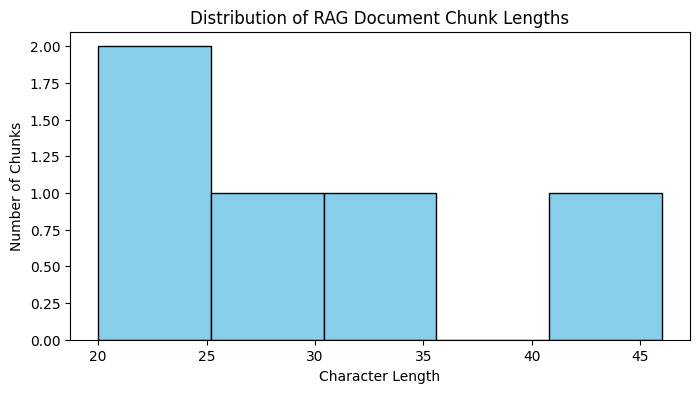

In [7]:
import logging
import matplotlib.pyplot as plt
from typing import Any, Dict, List

# Requirement 5: Write documentation for your implementation
class ProductionRAGSystem:
    """
    A production-ready RAG document processing system for a Digital Twin.
    It ingests raw text, validates it, logs the process, and visualizes document lengths.
    """
    
    def __init__(self, source_name: str = "Twin_Logs"):
        # Requirement 1: Combine concepts (Initialization)
        self.source_name = source_name
        self.processed_documents = []
        
        # Requirement 3: Include logging capabilities
        logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')
        self.logger = logging.getLogger("RAGSystem")
        self.logger.info(f"RAG System initialized for source: {self.source_name}")

    def process(self, input_data: Any) -> Dict[str, Any]:
        """Processes incoming text data into RAG-ready document chunks."""
        
        # Requirement 2: Comprehensive error handling
        if not isinstance(input_data, list):
            self.logger.error(f"Validation Error: Expected list, got {type(input_data).__name__}.")
            return {"status": "error", "message": "Input must be a list of strings."}
            
        if len(input_data) == 0:
            self.logger.warning("Empty list provided. Nothing to process.")
            return {"status": "error", "message": "Input list cannot be empty."}

        valid_chunks = 0
        for index, text in enumerate(input_data):
            if not isinstance(text, str):
                self.logger.error(f"Skipping item at index {index}: Not a string.")
                continue # Skip bad data instead of crashing
                
            if not text.strip():
                self.logger.warning(f"Skipping item at index {index}: Empty string.")
                continue

            # Process and format the document
            doc = {
                "id": f"doc_{len(self.processed_documents) + 1}",
                "text": text.strip(),
                "metadata": {
                    "source": self.source_name,
                    "length": len(text)
                }
            }
            self.processed_documents.append(doc)
            valid_chunks += 1

        self.logger.info(f"Successfully processed {valid_chunks} valid documents.")
        
        return {
            "status": "success", 
            "processed_count": valid_chunks,
            "total_in_db": len(self.processed_documents)
        }

    # Requirement 4: Create visualization of results
    def visualize_lengths(self):
        """Generates a histogram of document lengths to ensure balanced chunks."""
        if not self.processed_documents:
            self.logger.warning("No documents available to visualize.")
            return

        # Extract lengths from metadata
        lengths = [doc["metadata"]["length"] for doc in self.processed_documents]

        plt.figure(figsize=(8, 4))
        plt.hist(lengths, bins=5, color='skyblue', edgecolor='black')
        plt.title("Distribution of RAG Document Chunk Lengths")
        plt.xlabel("Character Length")
        plt.ylabel("Number of Chunks")
        plt.show()


# ==========================================
# Test your production system
# ==========================================
print("\n--- STARTING SYSTEM TESTS ---")

# Initialize the system
twin_rag = ProductionRAGSystem(source_name="Sensor_Manual_v1")

# Test 1: Valid Data
print("\n--- Test 1: Valid Data ---")
good_data = [
    "The pressure sensor reads in PSI.",
    "Voltage should not exceed 24V.",
    "If the light blinks red, check the connection."
]
twin_rag.process(good_data)

# Test 2: Bad Data (Wrong Type)
print("\n--- Test 2: Bad Data Type ---")
twin_rag.process(12345) # Should log an error

# Test 3: Mixed Data (List with some bad items)
print("\n--- Test 3: Mixed Valid/Invalid Data ---")
mixed_data = [
    "Valid sentence here.",
    404, # Bad data (int)
    "",  # Bad data (empty)
    "Another valid sentence."
]
twin_rag.process(mixed_data)

# Test 4: Visualize Results
print("\n--- Test 4: Visualization ---")
twin_rag.visualize_lengths()

Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

INFO: RAG System initialized.
INFO: Index built with 8 unique words.
INFO: Ingested 2 chunks from Test_Log.
INFO: RAG System initialized.
INFO: Index built with 8 unique words.
INFO: Ingested 2 chunks from Test_Log.
ERROR: Invalid input: Text must be a non-empty string.
INFO: RAG System initialized.
INFO: Index built with 8 unique words.
INFO: Ingested 2 chunks from Test_Log.



--- Starting Unit Tests ---


INFO: Retrieved 2 chunks for query: 'pressure sensor'
FAIL: test_chunking (__main__.TestRAGSystem.test_chunking)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "C:\Users\san\AppData\Local\Temp\ipykernel_9148\1359250146.py", line 140, in test_chunking
    self.assertEqual(len(self.rag.chunks), 3)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: 2 != 3

----------------------------------------------------------------------
Ran 3 tests in 0.187s

FAILED (failures=1)
INFO: RAG System initialized.
INFO: Index built with 30 unique words.
INFO: Ingested 3 chunks from System_Logs_Oct.
INFO: Retrieved 1 chunks for query: 'What happens if pressure is high?'



--- Initializing Digital Twin RAG ---

--- Querying the System ---
User Query: What happens if pressure is high?

--- AI Context Window (Retrieved Chunk) ---
Text: 'reading 150 psi log 103 action required if pressure exceeds 160 psi initiate emergency shutdown'
Metadata: {'source': 'System_Logs_Oct', 'word_count': 15}

--- Generating Visualization ---


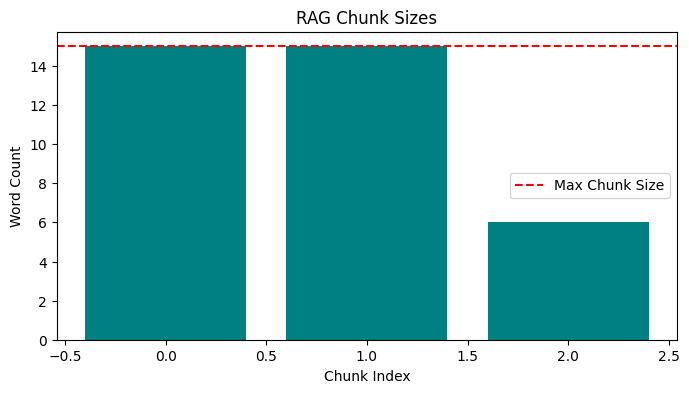

In [8]:
import re
import math
import logging
import unittest
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Dict, Any
from collections import Counter

# ==========================================
# 1. SETUP LOGGING
# ==========================================
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')
logger = logging.getLogger("TwinRAG")

# ==========================================
# 2. THE RAG PIPELINE CLASS
# ==========================================
class DigitalTwinRAG:
    """
    A complete RAG pipeline for a Digital Twin.
    Handles ingestion, chunking, embedding (simulated), indexing, and retrieval.
    """
    def __init__(self, chunk_size: int = 50):
        self.chunk_size = chunk_size
        self.chunks = []           # List of dictionaries (text + metadata)
        self.vocabulary = set()    # All unique words seen
        self.index = {}            # Inverted index (word -> list of chunk IDs)
        
        logger.info("RAG System initialized.")

    # --- Step 1: Ingestion & Chunking ---
    def _clean_and_chunk(self, text: str) -> List[str]:
        """Cleans text and splits it into word chunks."""
        text = re.sub(r'[^\w\s]', '', text.lower()) # Remove punctuation
        words = text.split()
        
        chunks = []
        for i in range(0, len(words), self.chunk_size):
            chunk_words = words[i:i + self.chunk_size]
            chunks.append(" ".join(chunk_words))
        return chunks

    # --- Step 2: Embedding & Indexing ---
    def _build_index(self):
        """Creates an inverted index for fast keyword retrieval."""
        self.index = {}
        for idx, chunk_data in enumerate(self.chunks):
            words = chunk_data['text'].split()
            for word in set(words): # Use set to avoid duplicates per chunk
                if word not in self.index:
                    self.index[word] = []
                self.index[word].append(idx)
        logger.info(f"Index built with {len(self.index)} unique words.")

    def ingest_data(self, raw_text: str, source: str):
        """
        Takes raw text, chunks it, creates metadata, and builds the search index.
        (Requirement: Handle edge cases)
        """
        if not isinstance(raw_text, str) or not raw_text.strip():
            logger.error("Invalid input: Text must be a non-empty string.")
            return False

        raw_chunks = self._clean_and_chunk(raw_text)
        
        for chunk in raw_chunks:
            if not chunk.strip(): continue
            
            self.chunks.append({
                "id": len(self.chunks),
                "text": chunk,
                "metadata": {
                    "source": source,
                    "word_count": len(chunk.split())
                }
            })
            # Track vocabulary
            self.vocabulary.update(chunk.split())

        self._build_index()
        logger.info(f"Ingested {len(raw_chunks)} chunks from {source}.")
        return True

    # --- Step 3: Retrieval ---
    def retrieve(self, query: str, top_k: int = 2) -> List[Dict]:
        """
        Retrieves the most relevant chunks based on keyword overlap.
        """
        if not isinstance(query, str) or not query.strip():
            logger.warning("Empty query provided.")
            return []

        query_words = re.sub(r'[^\w\s]', '', query.lower()).split()
        
        # Score chunks based on how many query words they contain
        scores = Counter()
        for word in query_words:
            if word in self.index:
                for chunk_id in self.index[word]:
                    scores[chunk_id] += 1

        # Get top K results
        top_chunk_ids = [cid for cid, score in scores.most_common(top_k)]
        
        results = [self.chunks[cid] for cid in top_chunk_ids]
        logger.info(f"Retrieved {len(results)} chunks for query: '{query}'")
        return results

    # --- Step 4: Visualization ---
    def visualize_chunks(self):
        """Visualizes the word count of all ingested chunks."""
        if not self.chunks:
            logger.warning("No data to visualize.")
            return

        lengths = [c['metadata']['word_count'] for c in self.chunks]
        
        plt.figure(figsize=(8, 4))
        plt.bar(range(len(lengths)), lengths, color='teal')
        plt.title("RAG Chunk Sizes")
        plt.xlabel("Chunk Index")
        plt.ylabel("Word Count")
        plt.axhline(y=self.chunk_size, color='red', linestyle='--', label='Max Chunk Size')
        plt.legend()
        plt.show()


# ==========================================
# 3. UNIT TESTS (Bonus Challenge)
# ==========================================
class TestRAGSystem(unittest.TestCase):
    def setUp(self):
        self.rag = DigitalTwinRAG(chunk_size=5)
        self.sample_text = "The pressure sensor is high. Check the pressure valve immediately."
        self.rag.ingest_data(self.sample_text, "Test_Log")

    def test_chunking(self):
        # 12 words total, chunk size 5 should create 3 chunks
        self.assertEqual(len(self.rag.chunks), 3)

    def test_retrieval(self):
        results = self.rag.retrieve("pressure sensor")
        self.assertGreater(len(results), 0)
        self.assertIn("pressure", results[0]['text'])

    def test_invalid_input(self):
        self.assertFalse(self.rag.ingest_data(12345, "Bad_Data"))
        self.assertEqual(len(self.rag.retrieve("")), 0)


# ==========================================
# 4. USER INTERFACE & EXECUTION
# ==========================================
def run_system():
    print("\n--- Starting Unit Tests ---")
    # Run tests programmatically (suppress output for clean notebook view)
    suite = unittest.TestLoader().loadTestsFromTestCase(TestRAGSystem)
    unittest.TextTestRunner(verbosity=0).run(suite)

    print("\n--- Initializing Digital Twin RAG ---")
    twin_rag = DigitalTwinRAG(chunk_size=15)

    # Integration: Simulate pulling a messy log file from your Digital Twin
    raw_manual = """
    [LOG 101] System starting up. Temp is 70F.
    [LOG 102] Warning: Pressure valve B is reading 150 PSI.
    [LOG 103] Action required: If pressure exceeds 160 PSI, initiate emergency shutdown immediately.
    [LOG 104] Normal operations resumed.
    """
    
    twin_rag.ingest_data(raw_manual, "System_Logs_Oct")

    print("\n--- Querying the System ---")
    query = "What happens if pressure is high?"
    print(f"User Query: {query}")
    
    retrieved_docs = twin_rag.retrieve(query, top_k=1)
    
    print("\n--- AI Context Window (Retrieved Chunk) ---")
    if retrieved_docs:
        best_doc = retrieved_docs[0]
        print(f"Text: '{best_doc['text']}'")
        print(f"Metadata: {best_doc['metadata']}")
    else:
        print("No relevant information found.")

    print("\n--- Generating Visualization ---")
    twin_rag.visualize_chunks()

# Execute the system
run_system()